---
title: "Lab 7: Basics of AWS"
subtitle: "Local Notebook: Visualize and Interpret"
author: "Shiqi Wu"
format:
  html:
    embed-resources: true
    code-overflow: wrap
execute:
  enabled: false
---

# Lab, Local Notebook: Visualize and Interpret

**GSB 5544 · Computing and Machine Learning for Business Analytics**

Open this notebook in **Positron, on your laptop**. It needs the three files you downloaded from your SageMaker space, in the same folder as this notebook:

- `lab_hot_days.csv`
- `lab_monthly_rain.csv`
- `lab_remote_measurements.json`

Everything here runs on your laptop. No cell in this notebook reads from S3.

In [1]:
# RUNS ON: laptop (Positron)
%pip install -q pandas pyarrow s3fs psutil matplotlib      # harmless if already present

import os
import json
import time
import socket
import psutil
import pandas as pd
import matplotlib.pyplot as plt

BUCKET = "noaa-ghcn-pds"


def human(n, base=1000):
    """Turn a byte count into a readable string. base=1000 gives KB/MB/GB; base=1024 gives KiB/MiB/GiB."""
    units = ["B", "KB", "MB", "GB", "TB", "PB"] if base == 1000 else ["B", "KiB", "MiB", "GiB", "TiB", "PiB"]
    for unit in units:
        if n < base:
            return f"{n:,.1f} {unit}"
        n /= base
    return f"{n:,.1f} (huge)"


def where_am_i():
    """Report which computer this kernel is really on. A RUNS ON comment cannot do that."""
    on_sagemaker = (os.path.exists("/opt/ml/metadata/resource-metadata.json")
                    or os.path.expanduser("~") == "/home/sagemaker-user")
    place = "SageMaker (remote)" if on_sagemaker else "not SageMaker (probably your laptop)"
    print("Computer name   :", socket.gethostname())
    print("This looks like :", place)
    return place


def machine_report(work_dir="."):
    """Measure the computer running this cell. Disk numbers are for the filesystem that holds work_dir."""
    vm = psutil.virtual_memory()
    du = psutil.disk_usage(work_dir)
    return {
        "computer name":                    socket.gethostname(),
        "physical CPU cores":               psutil.cpu_count(logical=False),   # may be None on some virtual machines
        "logical CPUs (vCPUs in the cloud)": psutil.cpu_count(logical=True),
        "total RAM (GB)":                   round(vm.total / 1e9, 1),
        "available RAM right now (GB)":     round(vm.available / 1e9, 1),
        "work disk, total (GB)":            round(du.total / 1e9, 1),
        "work disk, free (GB)":             round(du.free / 1e9, 1),
    }


if where_am_i() == "SageMaker (remote)":
    print()
    print("NOTE: this notebook is written to run on your laptop, in Positron, and this kernel is on SageMaker.")
    print("      Download this file and open it in Positron instead.")

Note: you may need to restart the kernel to use updated packages.
Computer name   : Shiqis-MBP-9.lan
This looks like : not SageMaker (probably your laptop)


In [2]:
# RUNS ON: laptop (Positron)
NEEDED = ["lab_hot_days.csv", "lab_monthly_rain.csv", "lab_remote_measurements.json"]
missing = [name for name in NEEDED if not os.path.exists(name)]
print("This notebook is running in:", os.getcwd())
print("MISSING: " + ", ".join(missing) if missing else "All three downloaded files are here.")

This notebook is running in: /Users/shiqi/Desktop/Fall 2026/Computing and Machine Learning/Labs/Lab 7
All three downloaded files are here.


## L8. Read what you downloaded

Read the two CSV files into `hot_days` and `monthly_rain`, and the JSON file into `REMOTE`. Print each table's shape and the size on disk of each downloaded file.

In [3]:
# RUNS ON: laptop (Positron)

hot_days = pd.read_csv("lab_hot_days.csv")
monthly_rain = pd.read_csv("lab_monthly_rain.csv")

with open("lab_remote_measurements.json") as f:
    REMOTE = json.load(f)

print("hot_days shape:", hot_days.shape)
print("monthly_rain shape:", monthly_rain.shape)

print()
for name in NEEDED:
    print(name, human(os.path.getsize(name)))

hot_days shape: (20, 4)
monthly_rain shape: (24, 4)

lab_hot_days.csv 518.0 B
lab_monthly_rain.csv 571.0 B
lab_remote_measurements.json 402.0 B


## L9. Chart 1: hot days per year

One line per market: year on the x-axis, number of days at or above 35 °C on the y-axis. Label both axes with units, give the chart a title that says what it shows, and save it as `lab_hot_days.png`.

Before you plot, look at `days_reported`. If any market-year has far fewer than 365 reported days, say so in your interpretation in L11.

         market  year  days_reported
        Phoenix  2015            365
        Phoenix  2016            366
        Phoenix  2017            365
        Phoenix  2018            365
        Phoenix  2019            365
        Phoenix  2020            366
        Phoenix  2021            365
        Phoenix  2022            365
        Phoenix  2023            365
        Phoenix  2024            366
San Luis Obispo  2015            365
San Luis Obispo  2016            366
San Luis Obispo  2017            365
San Luis Obispo  2018            365
San Luis Obispo  2019            365
San Luis Obispo  2020            366
San Luis Obispo  2021            365
San Luis Obispo  2022            365
San Luis Obispo  2023            365
San Luis Obispo  2024            366


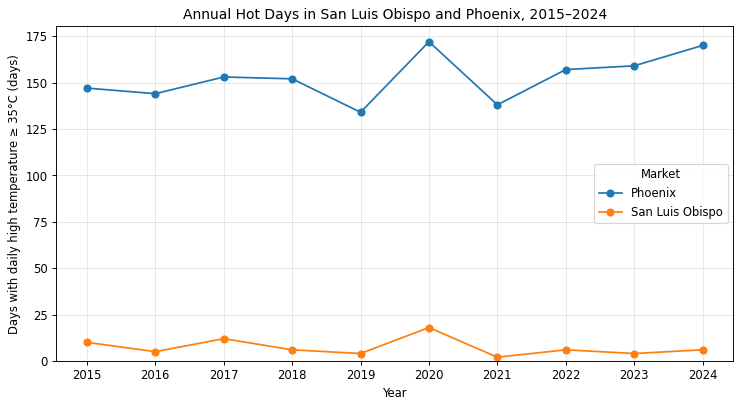

In [4]:
# RUNS ON: laptop (Positron)

print(hot_days[["market", "year", "days_reported"]].to_string(index=False))

plt.figure(figsize=(9, 5))

for market, data in hot_days.groupby("market"):
    data = data.sort_values("year")
    plt.plot(
        data["year"],
        data["hot_days"],
        marker="o",
        label=market
    )

plt.title("Annual Hot Days in San Luis Obispo and Phoenix, 2015–2024")
plt.xlabel("Year")
plt.ylabel("Days with daily high temperature ≥ 35°C (days)")
plt.xticks(sorted(hot_days["year"].unique()))
plt.ylim(bottom=0)
plt.legend(title="Market")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("lab_hot_days.png", dpi=300, bbox_inches="tight")
plt.show()

## L10. Chart 2: typical rainfall by month

Show the average monthly precipitation for both markets across the twelve calendar months, in millimeters, in a form that makes the two markets easy to compare. Save it as `lab_monthly_rain.png`. Then print the wettest month of each market.

Phoenix: wettest month = Aug, average rainfall = 24.3 mm
San Luis Obispo: wettest month = Jan, average rainfall = 147.1 mm


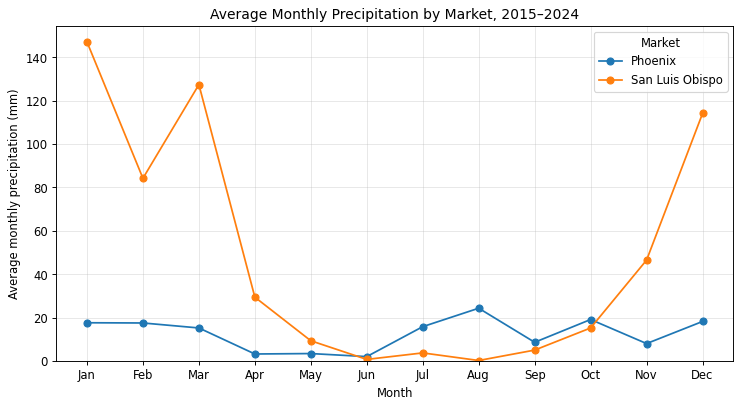

In [5]:
# RUNS ON: laptop (Positron)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(9, 5))

for market, data in monthly_rain.groupby("market"):
    data = data.sort_values("month")

    plt.plot(
        data["month"],
        data["avg_monthly_prcp_mm"],
        marker="o",
        label=market
    )

    wettest = data.loc[data["avg_monthly_prcp_mm"].idxmax()]
    month_name = month_names[int(wettest["month"]) - 1]
    rainfall = wettest["avg_monthly_prcp_mm"]
    print(f"{market}: wettest month = {month_name}, average rainfall = {rainfall:.1f} mm")

plt.title("Average Monthly Precipitation by Market, 2015–2024")
plt.xlabel("Month")
plt.ylabel("Average monthly precipitation (mm)")
plt.xticks(range(1, 13), month_names)
plt.ylim(bottom=0)
plt.legend(title="Market")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("lab_monthly_rain.png", dpi=300, bbox_inches="tight")
plt.show()

## L11. The business read

Answer as the inventory planner, in six to eight sentences, using numbers from your two charts.

- How differently should the two markets be stocked across the year? Refer to both heat and rain.
- Is there anything in `days_reported` or `years_used` that should make the team cautious about a particular year or month?
- Name **two** other datasets you would want to join to this weather history before trusting a demand model, and say where each one probably lives: on a laptop, in a company database, or in cloud storage.

*Your answer:*

Answer: I would plan for a larger hot weather beverage inventory buffer in Phoenix, which had 134–172 hot days per year, compared with only 2–18 in San Luis Obispo. However, these annual counts do not show exactly which months need more stock. San Luis Obispo's average rainfall ranges from 147.1 mm in January to 0.2 mm in August, so I would use different seasonal replenishment plans rather than one fixed plan all year. Phoenix's wettest month is August at 24.3 mm, and I would check whether this rainfall pattern affects sales or deliveries before changing orders. Every market-year has 365 or 366 reported temperature days, and every calendar-month average uses all 10 years, so these coverage measures do not flag a particular year or month. Still, monthly averages can hide unusual weather, and weather alone does not prove how much customers will buy. I would join daily sales by market and product, probably stored in the company database, to measure actual demand. I would also join pricing and promotion records, probably stored in the company database, to separate weather-related patterns from discounts and marketing campaigns.

## L12. Two machines and four sizes

Build one table that puts your laptop's `machine_report()` beside the remote machine's (from `REMOTE["machine"]`). Then print, in readable units: the source size in S3, the size of the remote DataFrame, the combined size of the exported CSVs, and the combined size of the files as downloaded on this laptop.

In [6]:
# RUNS ON: laptop (Positron)

LAPTOP_MACHINE = machine_report()

machine_comparison = pd.DataFrame({
    "Laptop (Positron)": LAPTOP_MACHINE,
    "SageMaker (remote)": REMOTE["machine"]
})

display(machine_comparison)

DOWNLOADED_BYTES = sum(os.path.getsize(name) for name in NEEDED)

print("Source data in S3:", human(REMOTE["source bytes in S3"]))
print("Remote DataFrame:", human(REMOTE["DataFrame bytes"]))
print("Exported CSVs combined:", human(REMOTE["exported bytes"]))
print("Downloaded files combined (2 CSVs + JSON):", human(DOWNLOADED_BYTES))

,Laptop (Positron),SageMaker (remote)
computer name,Shiqis-MBP-9.lan,default
physical CPU cores,10,1
logical CPUs (vCPUs in the cloud),10,2
total RAM (GB),25.8,4.0
available RAM right now (GB),6.6,1.4
"work disk, total (GB)",994.6,5.3
"work disk, free (GB)",757.8,5.2


Source data in S3: 558.3 MB
Remote DataFrame: 2.8 MB
Exported CSVs combined: 1.1 KB
Downloaded files combined (2 CSVs + JSON): 1.5 KB


## L13. Where the work happened

**(a)** Answer each of the five questions in one or two sentences, with specifics from this lab.

1. Where is the original data stored? Answer: The original weather data is stored in NOAA's public `noaa-ghcn-pds` S3 bucket. This lab used the Parquet slices for TMAX and PRCP from 2015 through 2024.
2. Which computer performed the analysis? Answer: The SageMaker machine performed the analysis. It read the S3 slices, filtered and cleaned the two stations' observations, and calculated the hot-day and rainfall summaries.
3. What did I download? Answer: I downloaded `lab_hot_days.csv`, `lab_monthly_rain.csv`, `lab_remote_measurements.json`, and a saved copy of the completed remote notebook. I did not download the original S3 slices to my laptop.
4. Which computer created the visualization? Answer: My laptop created both visualizations in Positron using Matplotlib. It read the downloaded summaries and saved the charts as `lab_hot_days.png` and `lab_monthly_rain.png`.
5. How did the two machines compare? Answer: My laptop reported 10 logical CPUs and 25.8 GB of total RAM, with 6.6 GB available, compared with 2 vCPUs and 4.0 GB of total RAM, with 1.4 GB available, on SageMaker. My laptop had more reported resources, but these measurements alone do not prove which machine would complete the same analysis faster.

**(b)** This weather summary will be refreshed **every week** once the demand model is live. Would you run the weekly refresh on your laptop or on a SageMaker space? Give two reasons that use what you measured: the source size, the size of what comes home, the resources of each machine, and the cost from L7.

Your answer: I would use a SageMaker space for the weekly refresh, even though my laptop has more RAM. First, the source slices total 558.3 MB in S3, while the two summary CSVs total only about 1.1 KB, so I can keep the extraction in AWS and bring home only the small results. Second, the remote machine successfully completed the extraction with 4.0 GB of total RAM, and L7 estimated a compute cost of about 0.129 dollars for 2.57 running hours. That is this session's estimate, not a fixed price for every weekly refresh. I would stop the space immediately after each refresh to avoid paying for unused running time.

## L14. Save and stop

- [ ] **Remote notebook:** File → **Save Notebook**. Right-click it in the JupyterLab file browser and **Download** a copy.
- [ ] **Studio tab:** on the `gsb5544` space page click **Stop space**, confirm in the dialog, and wait until the status reads **Stopped**. Closing the browser tab does not stop it.
- [ ] **Console Home** (open [console.aws.amazon.com](https://console.aws.amazon.com) in a new tab): read **Credits remaining** and note it. The panel can lag by several hours.
- [ ] **Laptop:** save your local notebook in Positron (Cmd+S, or Ctrl+S on Windows).

Paste a screenshot of the `gsb5544` space page showing status **Stopped** into the cell below, or submit it as a separate image.

Evidence: On October 18, 2026, AWS Console Home showed 99.64 dollars in credits remaining. This balance may not yet include all recent charges. The `gsb5544` space was stopped, and I saved the screenshot as a separate submission file.

## What to submit

1. `04_lab_remote.ipynb`, run in SageMaker, with output showing.
2. `04_lab_local.ipynb` (this notebook), run in Positron, with output and written answers.
3. `lab_hot_days.csv` and `lab_monthly_rain.csv`.
4. `lab_hot_days.png` and `lab_monthly_rain.png`.
5. The screenshot showing the space **Stopped**.

A submission is graded on both halves. A lab whose charts were made on SageMaker, or whose summaries were computed on a laptop, has not done the workflow.